# Sprint 2 - EDA and Graphs
I will use the cleaned file with 994 rows. For each graph I will write what I see, what it means, and what shop should do.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = pd.read_csv('Laptop_price_cleaned_final.csv')
print(df.shape)
print(df.describe().round(2))


(994, 7)
       Processor_Speed  RAM_Size  Storage_Capacity  Screen_Size  Weight  \
count           994.00    994.00            994.00       994.00  994.00   
mean              2.76     15.43            583.66        14.06    3.47   
std               0.72     10.84            310.52         1.68    0.86   
min               1.51      4.00            256.00        11.01    2.00   
25%               2.11      8.00            256.00        12.67    2.73   
50%               2.78     16.00            512.00        14.10    3.47   
75%               3.35     32.00           1000.00        15.50    4.19   
max               4.00     32.00           1000.00        16.99    4.99   

          Price  
count    994.00  
mean   19490.47  
std     9308.61  
min     8570.01  
25%    10154.56  
50%    17272.01  
75%    31551.13  
max    33503.94  


## Step 1 - Average table

In [2]:
# mean, median, min, max
print(df[['Processor_Speed','RAM_Size','Storage_Capacity','Screen_Size','Weight','Price']].mean().round(2))
print(df[['Processor_Speed','RAM_Size','Storage_Capacity','Screen_Size','Weight','Price']].median().round(2))
print(df['Price'].min(), df['Price'].max(), df['Price'].std().round(2))


Processor_Speed         2.76
RAM_Size               15.43
Storage_Capacity      583.66
Screen_Size            14.06
Weight                  3.47
Price               19490.47
dtype: float64
Processor_Speed         2.78
RAM_Size               16.00
Storage_Capacity      512.00
Screen_Size            14.10
Weight                  3.47
Price               17272.01
dtype: float64
8570.01295046808 33503.93503731473 9308.61


Price mean is 19490 and median is 17272. Min is 8570 and max is 33503. Difference is big, so prices vary a lot.

## Step 2 - Single column graphs

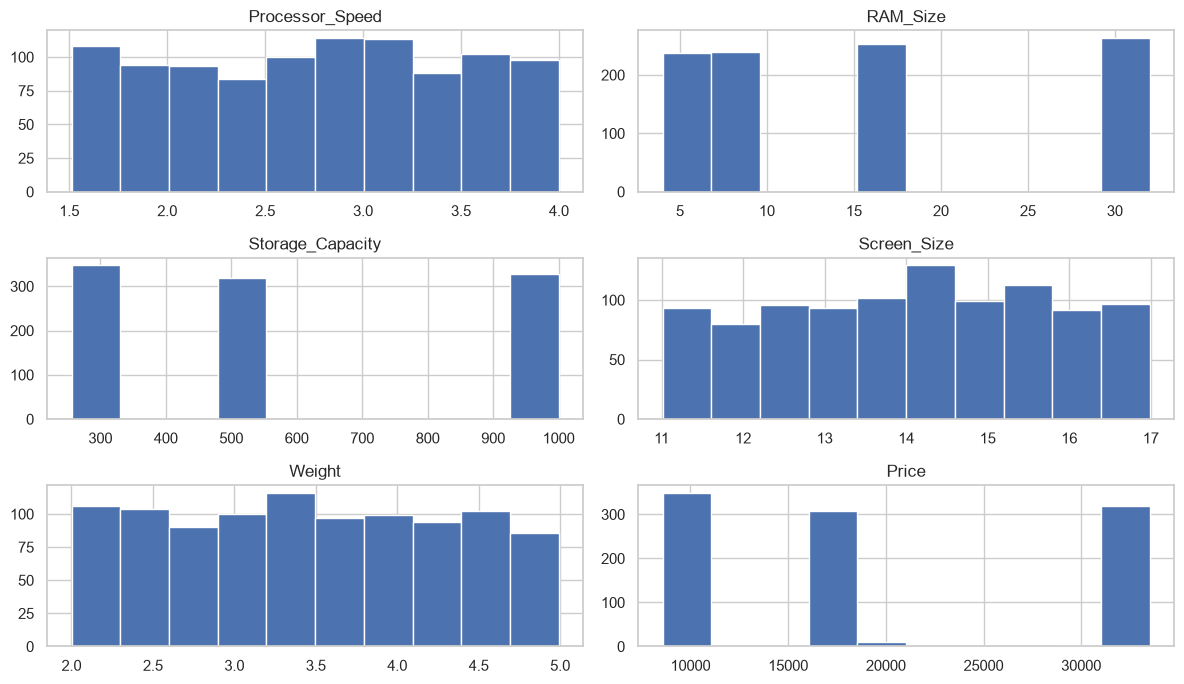

In [3]:
df[['Processor_Speed','RAM_Size','Storage_Capacity','Screen_Size','Weight','Price']].hist(figsize=(12,7))
plt.tight_layout()
plt.savefig('visuals/s2_univariate_hist.png', dpi=120)
plt.show()


What I see: Processor, Screen and Weight look almost normal. RAM, Storage and Price are bent to right side. What it means: RAM and Storage have fixed options, Price has budget group and premium group. Shop learning: keep products in groups, not one average price.

## Step 3 - Brand study

In [4]:
print(df['Brand'].value_counts())
print((df['Brand'].value_counts(normalize=True)*100).round(1))


Brand
Dell      214
Asus      203
Acer      202
HP        188
Lenovo    187
Name: count, dtype: int64
Brand
Dell      21.5
Asus      20.4
Acer      20.3
HP        18.9
Lenovo    18.8
Name: proportion, dtype: float64


Brand
Dell      18766.8
HP        19237.3
Asus      19721.8
Acer      19793.8
Lenovo    19994.4
Name: Price, dtype: float64


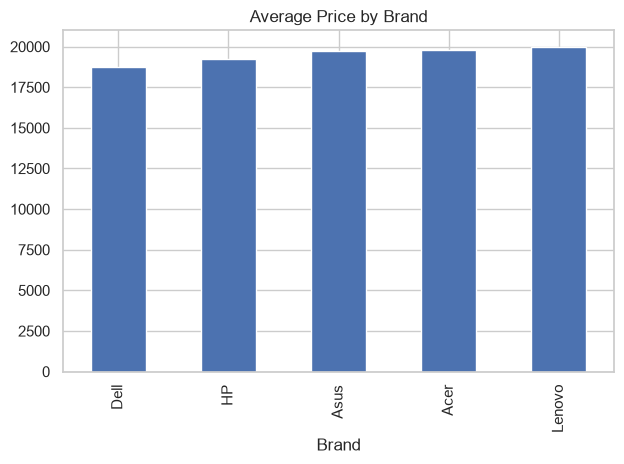

In [5]:
brand_avg = df.groupby('Brand')['Price'].mean().sort_values()
print(brand_avg.round(1))
brand_avg.plot(kind='bar', title='Average Price by Brand')
plt.tight_layout()
plt.savefig('visuals/s2_brand_avgprice.png', dpi=120)
plt.show()


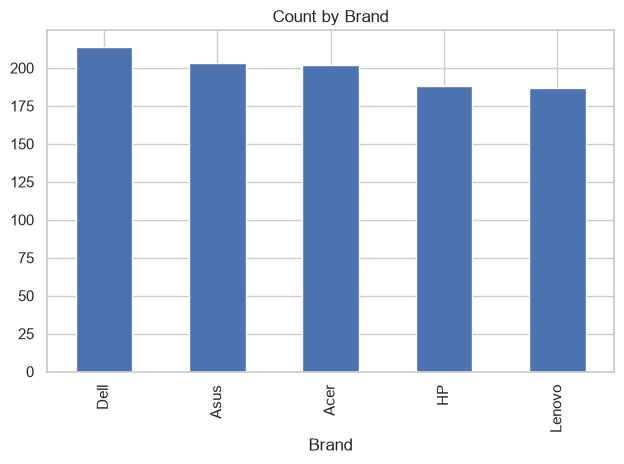

In [6]:
df['Brand'].value_counts().plot(kind='bar', title='Count by Brand')
plt.tight_layout()
plt.savefig('visuals/s2_brand_counts.png', dpi=120)
plt.show()


What I see: Dell has most laptops (214), Lenovo has least (187). Average price: Lenovo 19994 is highest, Dell 18767 is lowest. Difference is only about 1200. What it means: no brand is very costly or very cheap. Shop learning: Dell can be shown as value option, Lenovo as premium option.

## Step 4 - Price study

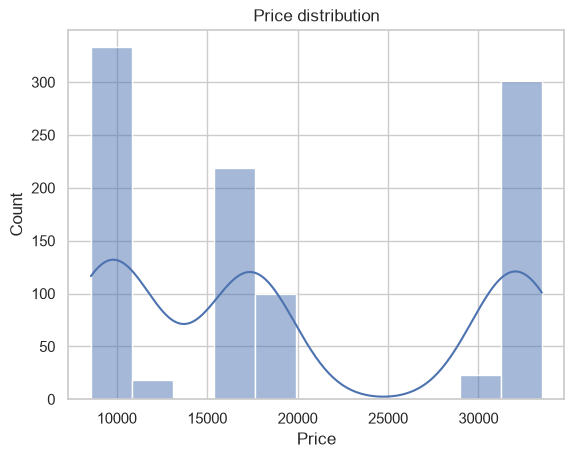

In [7]:
sns.histplot(df['Price'], kde=True)
plt.title('Price distribution')
plt.savefig('visuals/s2_price_hist.png', dpi=120)
plt.show()


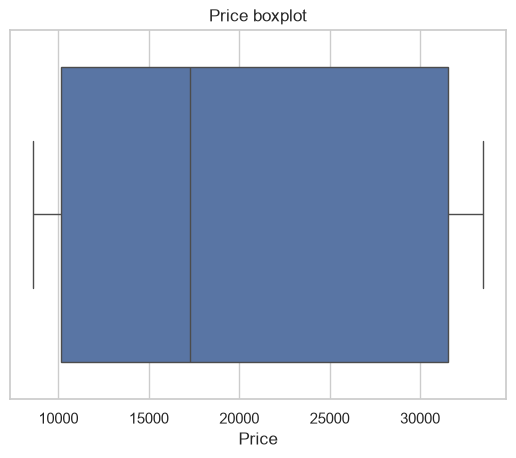

In [8]:
sns.boxplot(x=df['Price'])
plt.title('Price boxplot')
plt.savefig('visuals/s2_price_box.png', dpi=120)
plt.show()


What I see: average price is high because some premium laptops pull it up. There are two groups, one near 10000 and one near 31000. What it means: market has budget and premium parts. Shop learning: keep separate budget, mid and premium models.

## Step 5 - Two columns together

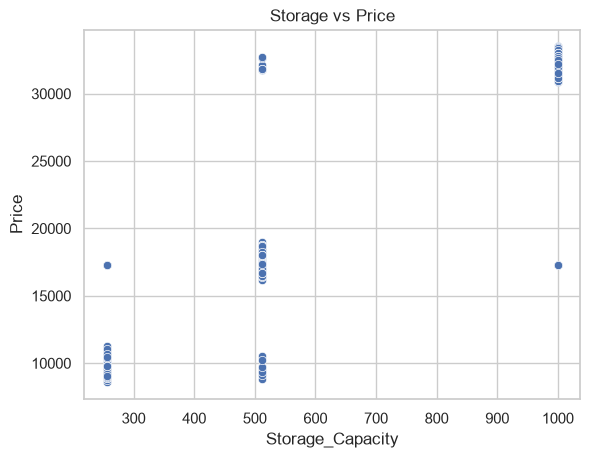

In [9]:
sns.scatterplot(x=df['Storage_Capacity'], y=df['Price'])
plt.title('Storage vs Price')
plt.savefig('visuals/s2_biv_Storage_Capacity.png', dpi=120)
plt.show()


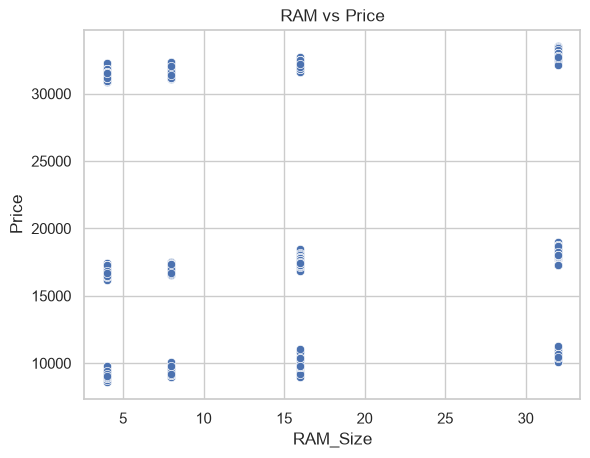

In [10]:
sns.scatterplot(x=df['RAM_Size'], y=df['Price'])
plt.title('RAM vs Price')
plt.savefig('visuals/s2_biv_RAM_Size.png', dpi=120)
plt.show()


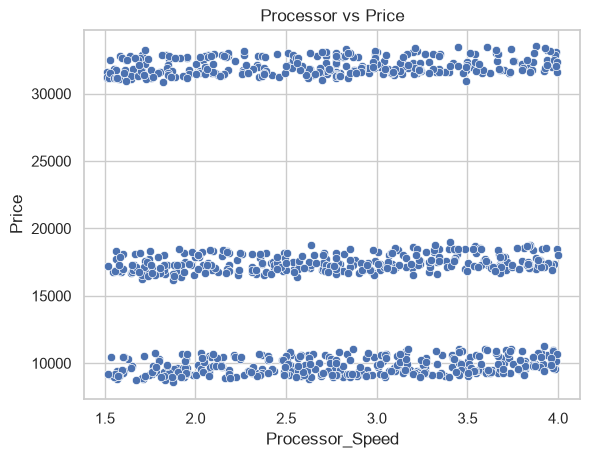

In [11]:
sns.scatterplot(x=df['Processor_Speed'], y=df['Price'])
plt.title('Processor vs Price')
plt.savefig('visuals/s2_biv_Processor_Speed.png', dpi=120)
plt.show()


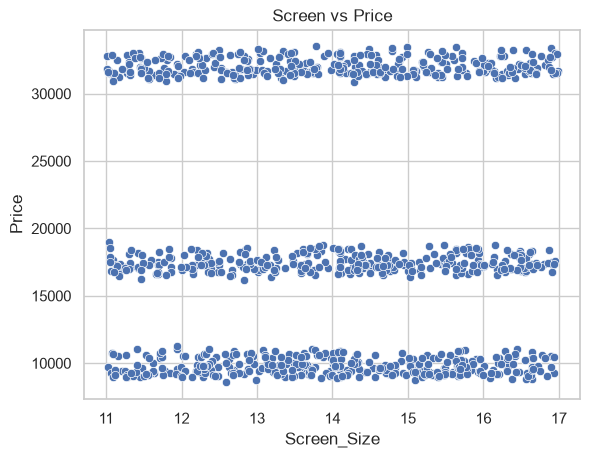

In [12]:
sns.scatterplot(x=df['Screen_Size'], y=df['Price'])
plt.title('Screen vs Price')
plt.savefig('visuals/s2_biv_Screen_Size.png', dpi=120)
plt.show()


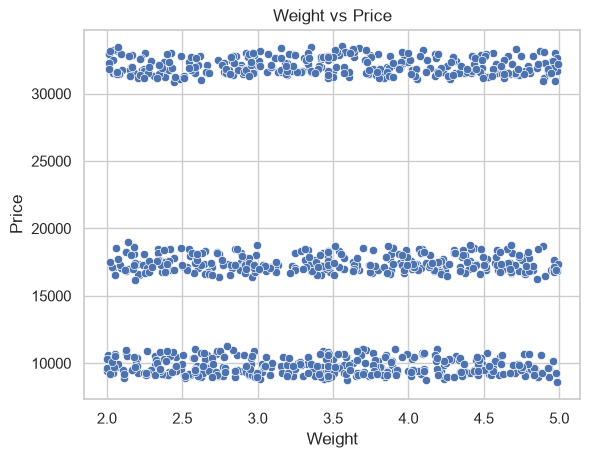

In [13]:
sns.scatterplot(x=df['Weight'], y=df['Price'])
plt.title('Weight vs Price')
plt.savefig('visuals/s2_biv_Weight.png', dpi=120)
plt.show()


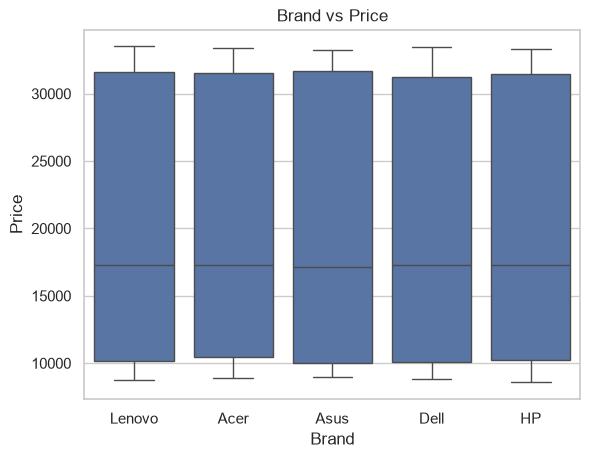

In [14]:
sns.boxplot(x='Brand', y='Price', data=df)
plt.title('Brand vs Price')
plt.savefig('visuals/s2_biv_brand.png', dpi=120)
plt.show()


What I see: Storage vs Price goes clearly up in steps. RAM vs Price goes up only a little. Processor, Screen, Weight show flat cloud, no clear line. Brand boxes overlap. What it means: Storage decides price most. Shop learning: price list should be based on storage first.

## Step 6 - Three columns together

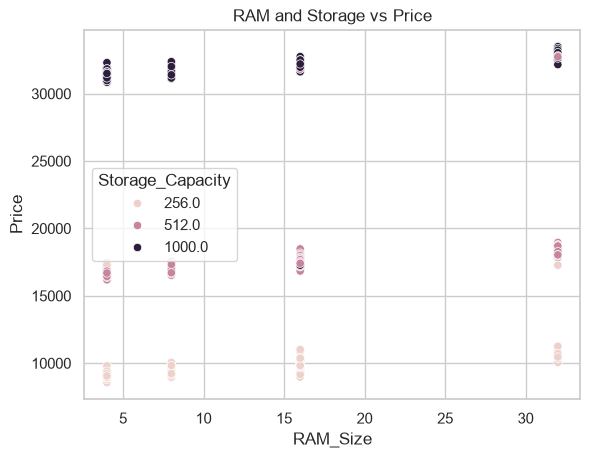

In [15]:
sns.scatterplot(data=df, x='RAM_Size', y='Price', hue='Storage_Capacity')
plt.title('RAM and Storage vs Price')
plt.savefig('visuals/s2_multi_ram_storage.png', dpi=120)
plt.show()


In [16]:
print(pd.pivot_table(df, values='Price', index='RAM_Size', columns='Storage_Capacity', aggfunc='mean').round(0))


Storage_Capacity   256.0    512.0    1000.0
RAM_Size                                   
4.0                9274.0  16682.0  31078.0
8.0                9492.0  17015.0  30998.0
16.0               9949.0  17641.0  31298.0
32.0              10730.0  18502.0  32885.0


What I see: 32GB + 1TB average is 32885, but 4GB + 256GB average is only 9274. Same RAM with 1TB costs 2 to 3 times more. What it means: RAM and Storage together increase price. Shop learning: sell high RAM only with 1TB, and sell 16GB + 512GB as normal mid-range model.

## Step 7 - Groupby

In [17]:
print(df.groupby('Brand')['Price'].mean().round(1))
print(df.groupby('RAM_Size')['Price'].median().round(1))
print(df.groupby('Storage_Capacity')['Price'].mean().round(1))


Brand
Acer      19793.8
Asus      19721.8
Dell      18766.8
HP        19237.3
Lenovo    19994.4
Name: Price, dtype: float64
RAM_Size
4.0     16845.8
8.0     17043.7
16.0    17402.1
32.0    18224.9
Name: Price, dtype: float64
Storage_Capacity
256.0      9879.1
512.0     17493.0
1000.0    31601.3
Name: Price, dtype: float64


Storage group means: 256GB = 9879, 512GB = 17493, 1TB = 31601. RAM medians: 4GB = 16846, 8GB = 17044, 16GB = 17402, 32GB = 18225. So storage effect is very big, RAM effect is small.

## Step 8 - Pivot tables

In [18]:
print(pd.pivot_table(df, values='Price', index='Brand', columns='RAM_Size', aggfunc='mean').round(0))
print(pd.pivot_table(df, values='Price', index='Brand', columns='Storage_Capacity', aggfunc='mean').round(0))
print(pd.pivot_table(df, values='Price', index='RAM_Size', columns='Storage_Capacity', aggfunc='mean').round(0))


RAM_Size     4.0      8.0      16.0     32.0
Brand                                       
Acer      18802.0  20660.0  16746.0  22689.0
Asus      18073.0  20662.0  18854.0  20967.0
Dell      16943.0  18554.0  19894.0  19340.0
HP        19850.0  17198.0  20111.0  19070.0
Lenovo    18852.0  20240.0  18720.0  21635.0
Storage_Capacity   256.0    512.0    1000.0
Brand                                      
Acer               9833.0  17264.0  31670.0
Asus               9787.0  17464.0  31613.0
Dell               9945.0  17426.0  31145.0
HP                 9696.0  17418.0  31702.0
Lenovo            10118.0  17985.0  31875.0


Storage_Capacity   256.0    512.0    1000.0
RAM_Size                                   
4.0                9274.0  16682.0  31078.0
8.0                9492.0  17015.0  30998.0
16.0               9949.0  17641.0  31298.0
32.0              10730.0  18502.0  32885.0


What I see: Brand x Storage table is almost same for all brands. 1TB is 31145 to 31875 for every brand. What it means: storage price rule is same in full market, not brand special.

## Step 9 - Crosstab

In [19]:
q33 = df['Price'].quantile(0.33)
q66 = df['Price'].quantile(0.66)
print(q33, q66)

df['Price_Cat'] = pd.cut(df['Price'], bins=[-1, float(q33), float(q66), float(df['Price'].max()+1)], labels=['Budget','Mid-Range','Premium'])
df['RAM_Cat'] = pd.cut(df['RAM_Size'], bins=[-1, 8, 16, 100], labels=['Low (4-8GB)','Medium (16GB)','High (32GB)'])
df['Storage_Cat'] = df['Storage_Capacity'].map({256:'Small (256GB)', 512:'Medium (512GB)', 1000:'Large (1TB)'})

print(pd.crosstab(df['Brand'], df['Price_Cat']))
print(pd.crosstab(df['Brand'], df['RAM_Cat']))
print(pd.crosstab(df['Brand'], df['Storage_Cat']))


10741.551543822692 18502.85318894485


Price_Cat  Budget  Mid-Range  Premium
Brand                                
Acer           61         74       67
Asus           70         58       75
Dell           75         75       64
HP             59         68       61
Lenovo         63         53       71
RAM_Cat  Low (4-8GB)  Medium (16GB)  High (32GB)
Brand                                           
Acer              96             50           56
Asus             109             50           44
Dell              93             53           68
HP                94             54           40
Lenovo            86             46           55
Storage_Cat  Large (1TB)  Medium (512GB)  Small (256GB)
Brand                                                  
Acer                  69              68             65
Asus                  72              58             73
Dell                  64              71             79
HP                    58              67             63
Lenovo                65              55             67

Price groups are almost equal: Budget 328, Mid 328, Premium 338. Every brand has all three groups. So no brand is only budget or only premium.

## Step 10 - Correlation

In [20]:
corr = df[['Processor_Speed','RAM_Size','Storage_Capacity','Screen_Size','Weight','Price']].corr()
print(corr['Price'].round(3))


Processor_Speed    -0.049
RAM_Size            0.077
Storage_Capacity    0.973
Screen_Size        -0.019
Weight              0.033
Price               1.000
Name: Price, dtype: float64


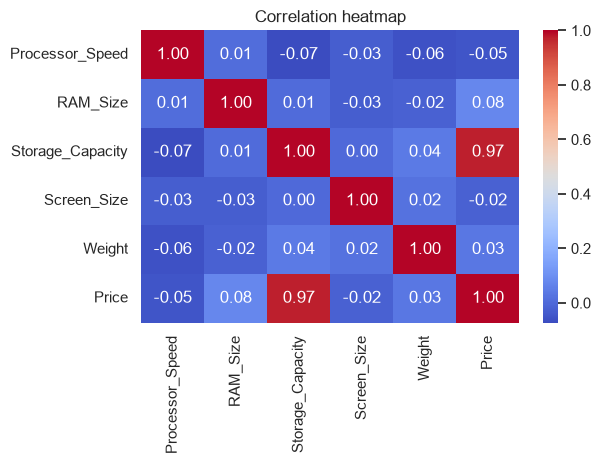

In [21]:
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.tight_layout()
plt.savefig('visuals/s2_corr_heatmap.png', dpi=120)
plt.show()


What I see: Storage and Price correlation is 0.97, very strong. RAM is 0.08, Weight 0.03, Screen -0.02, Processor -0.05, all very weak. What it means: only storage moves with price.

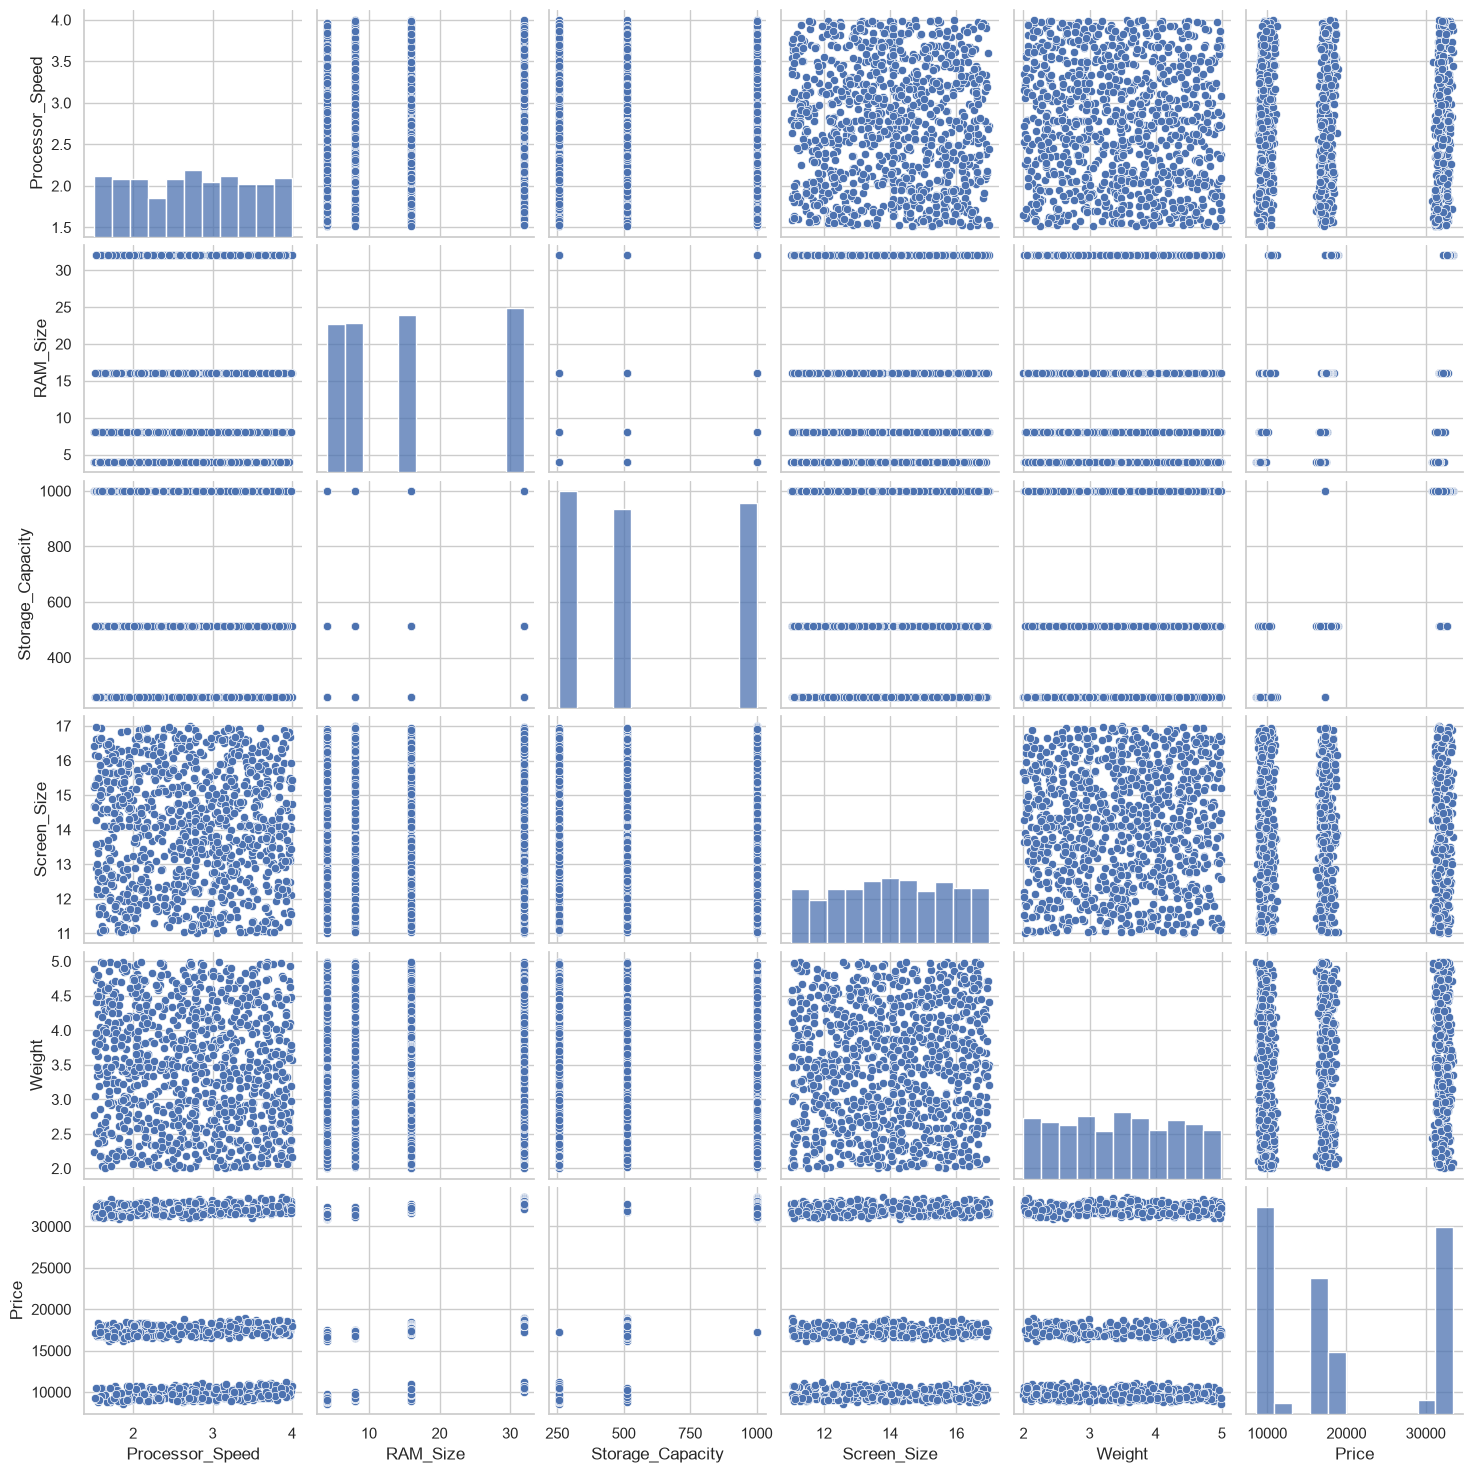

In [22]:
sns.pairplot(df[['Processor_Speed','RAM_Size','Storage_Capacity','Screen_Size','Weight','Price']])
plt.savefig('visuals/s2_pairplot.png', dpi=120)
plt.show()


## Final answers for shop
- Highest average price: Lenovo (19994). Lowest: Dell (18767).
- More RAM means a little more price, but not much.
- Storage decides price: 9879 to 31601.
- Strongest relation is Storage.
- All brands sell in budget, mid and premium.

My suggestion: make price steps by storage, keep 512GB + 16GB as main mid-range stock, use Dell for value and Lenovo for premium.